# F1 dataset: the simple version

**74 seasons of Formula 1 (1950–2023), explained step by step.**

This is a short version of `00_dataset_overview.ipynb`. It shows the same main findings with much less code:
about 90 lines in 15 cells, and every line is explained in plain words.

## 1. Tools

Python on its own cannot read tables or draw charts. We borrow two ready-made toolboxes (called *libraries*).

In [16]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (10, 4)

## 2. Loading the data

The data lives in three files in the `data` folder: `train.csv`, `validation.csv` and `test.csv`.


We load **all 55 columns** of every file. The files are big (1.4 GB together), so this cell takes about
half a minute and needs roughly 5 GB of memory. Be patient and run it only once.

In [17]:
tables = []
for name in ['train', 'validation', 'test']:
    table = pd.read_csv('data/' + name + '.csv', na_values='\\N', low_memory=False)
    table['file'] = name
    tables.append(table)

raw = pd.concat(tables, ignore_index=True)
print('Rows and columns in the raw files:', raw.shape)

Rows and columns in the raw files: (3536791, 56)


In [32]:
raw.columns

Index(['resultId', 'racerId', 'driverId', 'constructorId', 'number', 'grid',
       'position_x', 'positionText_x', 'positionOrder', 'points', 'laps',
       'time_x', 'timetaken_in_millisec', 'fastestLap', 'rank',
       'fastestLapTime', 'max_speed', 'statusId', 'year', 'round', 'circuitId',
       'grand_prix', 'date', 'time_y', 'url_x', 'fp1_date', 'fp1_time',
       'fp2_date', 'fp2_time', 'fp3_date', 'fp3_time', 'quali_date',
       'quali_time', 'sprint_date', 'sprint_time', 'driverRef', 'driver_num',
       'driver_code', 'forename', 'surname', 'dob', 'nationality', 'url_y',
       'driverStandingsId', 'raceId_y', 'points_y', 'position',
       'positionText_y', 'wins', 'constructorRef', 'company', 'nationality_y',
       'url', 'status', 'result_driver_standing', 'file'],
      dtype='str')

**The columns we use most**

There are too many columns to learn them all. These 11 are the ones this notebook works with
(the full dictionary of all columns is in `00_dataset_overview.ipynb`):

| Column | Meaning |
|---|---|
| `resultId` | ID of one result = one driver in one race. **This is our unit of observation.** |
| `racerId` | ID of the **race** (the name is misleading: it is not the driver!) |
| `driverId` | ID of the driver |
| `forename`, `surname` | the driver's name |
| `company` | the team (Ferrari, McLaren…) |
| `grand_prix` | the name of the race |
| `year` | the season |
| `grid` | starting position (1 = pole position, 0 = no normal start slot) |
| `positionOrder` | final position in the race. **This is what the project predicts.** |
| `status` | how the race ended for the driver (Finished, Engine, Accident…) |

**What we see:** over 3.5 million rows and 56 columns. That looks like a huge dataset. The next section shows that it is not.

## 3. The trap: every result is copied many times

Let's look at the first 5 rows of the table and at seven of its columns.

In [18]:
raw[['resultId', 'surname', 'grand_prix', 'grid', 'positionOrder', 'raceId_y', 'points_y']].head(5)

,resultId,surname,grand_prix,grid,positionOrder,raceId_y,points_y
0,20025,Farina,British Grand Prix,1,1,792,3.33
1,20025,Farina,British Grand Prix,1,1,793,6.33
2,20025,Farina,British Grand Prix,1,1,794,6.33
3,20025,Farina,British Grand Prix,1,1,795,10.33
4,20025,Farina,British Grand Prix,1,1,796,10.33


**What the code does**
- `raw[[...]]`: picks a few columns from the table. `.head(5)` shows the first 5 rows.

**What we see:** all five rows have the same `resultId` (20025). It is one result: Nino Farina at the British Grand Prix
of 1950, the very first F1 championship race. He started 1st and finished 1st. Those columns repeat.
Only `raceId_y` and `points_y` change.

**Why?** The organisers joined two tables incorrectly: race results and the championship standings.
Each result got the standings from *many different rounds* glued onto it, so one result became many rows.

In [19]:
print('Copies of result 20025:', (raw['resultId'] == 20025).sum())

df = raw.drop_duplicates('resultId')
print('Rows before:', len(raw))
print('Rows after: ', len(df))
print('Average number of copies:', round(len(raw) / len(df)))

Copies of result 20025: 48
Rows before: 3536791
Rows after:  26056
Average number of copies: 136


**What we see:** that single result appears 48 times. Overall, 3.5 million rows shrink to **26,056 real results**,
so each result was copied about 136 times on average.

**Is it safe to just keep the first copy?** For the columns that describe the race (driver, team, grid,
final position, status…) yes: they are identical in every copy.

**Careful:** the columns that come from the championship standings are different in every copy, so after this step
they hold a value from a random round. These are `driverStandingsId`, `raceId_y`, `points_y`, `position`,
`positionText_y`, `wins` and `result_driver_standing`. **We do not use them in this notebook.**
(The full notebook repairs them properly, which takes more code.)

> **Sentence to remember:** "The raw files suggest 3.5 million observations, but there are only about 26 thousand real ones."

## 4. The dataset in numbers

In [20]:
print('Results: ', len(df))
print('Seasons: ', df['year'].nunique(), 'from', df['year'].min(), 'to', df['year'].max())
print('Races:   ', df['racerId'].nunique())
print('Drivers: ', df['driverId'].nunique())
print('Teams:   ', df['company'].nunique())

Results:  26056
Seasons:  74 from 1950 to 2023
Races:    1091
Drivers:  850
Teams:    210


**What we see:** 74 seasons, 1,091 races, 850 drivers, 210 teams. The dataset covers practically the whole
history of Formula 1. Divide results by races: about 24 drivers per race on average.

## 5. Three files = three periods of time

The organisers did not split the data randomly. They split it **by time**.

In [21]:
df.groupby('file')['year'].agg(['min', 'max', 'count'])

,min,max,count
file,,,
test,2018,2023,2132
train,1950,2013,22089
validation,2013,2018,1835


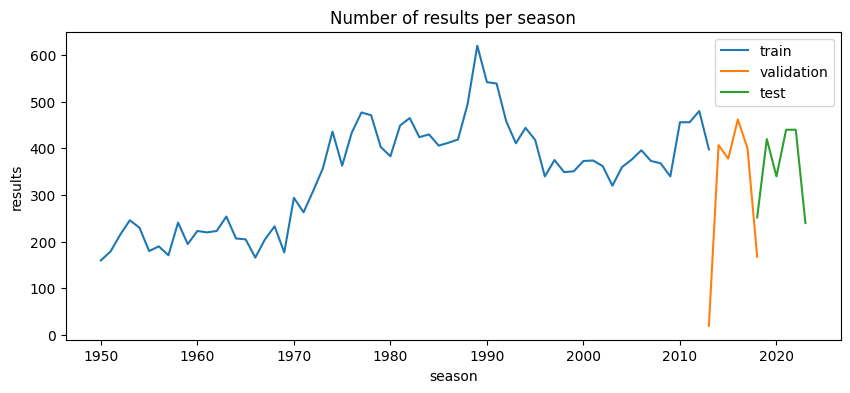

In [22]:
for name in ['train', 'validation', 'test']:
    part = df[df['file'] == name]
    part['year'].value_counts().sort_index().plot(label=name)

plt.title('Number of results per season')
plt.xlabel('season')
plt.ylabel('results')
plt.legend()
plt.show()

**What the code does**
- `df.groupby('file')`: splits the table into groups, one per file. `['year'].agg(['min', 'max', 'count'])`
  gives the first year, the last year and the number of rows for each group.
- `df[df['file'] == name]`: a **filter**. It keeps only the rows where the condition is true.
- `.value_counts()`: counts how many times each value (here: each year) appears. `.sort_index()` orders the years.
- `.plot(label=name)`: draws a line. The loop draws three lines, one per file.
- `plt.title`, `plt.xlabel`, `plt.ylabel`, `plt.legend`: title, axis names, legend. `plt.show()` displays the chart.

**What we see**
- **train** = 1950–2013 (22,089 results), **validation** = 2013–2018 (1,835), **test** = 2018–2023 (2,132).
  About 85% of the data is in train.
- The seasons 2013 and 2018 are each shared between two files, so the lines dip there. 2023 is only half a season.
- The peak around 1989–1991: over 30 cars entered each race in those years.

**Why split by time?** A model learns from the past and must predict the future, like in real life.
So we must never shuffle the rows or mix the files.

## 6. The target: what do we want to predict?

The *target* is the column a model tries to guess. Here it is `positionOrder`, the final position.
Guessing the exact position (1 to 39) is too hard, so the project groups it into **4 classes**:

| Class | Final position |
|---|---|
| **win** | 1 |
| **podium** | 2–3 |
| **points** | 4–10 |
| **rest** | 11 and worse |

result_class
win        1094
podium     2201
points     7686
rest      15075
Name: count, dtype: int64


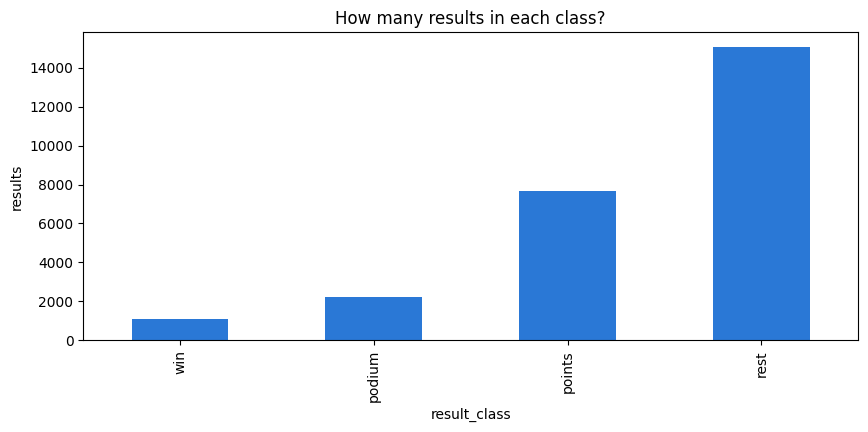

In [23]:
def to_class(position):
    if position == 1:
        return 'win'
    if position <= 3:
        return 'podium'
    if position <= 10:
        return 'points'
    return 'rest'

class_order = ['win', 'podium', 'points', 'rest']

df['result_class'] = df['positionOrder'].apply(to_class)
counts = df['result_class'].value_counts().loc[class_order]
print(counts)

counts.plot(kind='bar', color='#2a78d6', title='How many results in each class?')
plt.ylabel('results')
plt.show()

**What the code does**
- `def to_class(position):` defines our own small **function**: a recipe that takes a position and gives back a class name.
  It checks the conditions from top to bottom and stops at the first one that is true.
- `df['positionOrder'].apply(to_class)`: uses the recipe on every row. The answers go into a new column `result_class`.
- `.value_counts()`: counts the rows in each class. `.loc[class_order]` puts them in our order.
- `.plot(kind='bar')`: a bar chart.

**What we see:** the classes are very **unequal** (*imbalanced*): 1,094 wins (4%), 2,201 podiums (8%),
7,686 points (30%) and 15,075 rest (58%). There are about 14 times more "rest" than "win".

**Why it matters:** a lazy model that always answers "rest" would be right 58% of the time and still be useless.
That is why the project measures quality with **macro-F1**, a score that treats all four classes as equally important.

## 7. The starting grid: the strongest clue

Does the starting position decide the result? We look only at drivers with a normal start slot (`grid` above 0)
and at the first 20 slots.

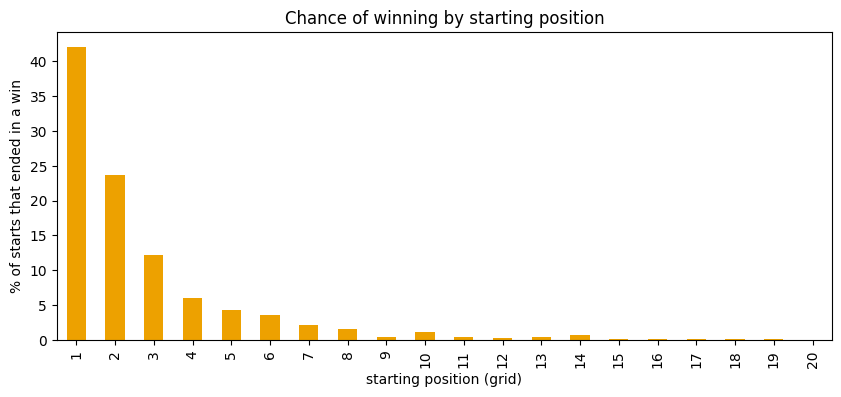

In [24]:
df['won'] = df['positionOrder'] == 1

front = df[(df['grid'] >= 1) & (df['grid'] <= 20)]
win_chance = front.groupby('grid')['won'].mean() * 100

win_chance.plot(kind='bar', color='#eda100', title='Chance of winning by starting position')
plt.xlabel('starting position (grid)')
plt.ylabel('% of starts that ended in a win')
plt.show()

**What the code does**
- `df['won'] = df['positionOrder'] == 1`: a new column that is True if the driver won, otherwise False.
- `df[(...) & (...)]`: a filter with two conditions. `&` means "and". Each condition needs its own brackets.
- `front.groupby('grid')['won'].mean()`: for each starting position, the average of `won`.
  The average of True/False values is simply the **share of Trues**. `* 100` turns it into a percentage.

**What we see:** the driver on pole position wins **42%** of the time. From 2nd place: 24%. From 3rd: 12%.
From 10th or further back a win is almost impossible (about 1% or less).

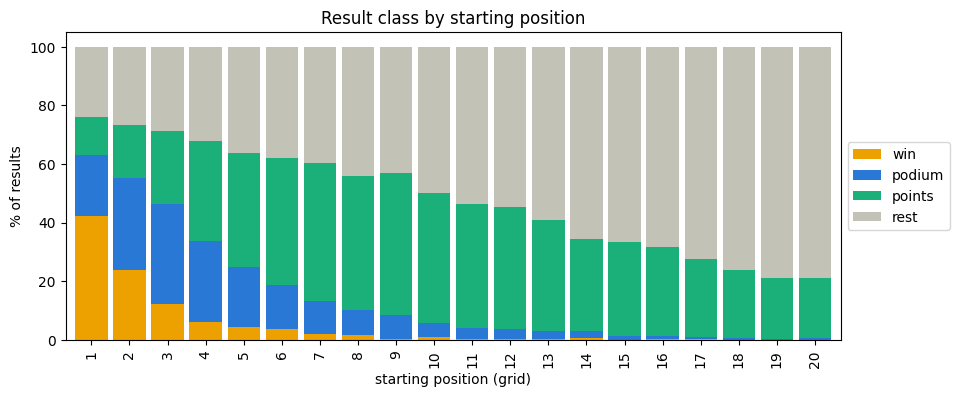

In [25]:
shares = pd.crosstab(front['grid'], front['result_class'], normalize='index') * 100

shares[class_order].plot(kind='bar', stacked=True, width=0.85,
                         color=['#eda100', '#2a78d6', '#1baf7a', '#c3c2b7'],
                         title='Result class by starting position')
plt.xlabel('starting position (grid)')
plt.ylabel('% of results')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.show()

**What the code does**
- `pd.crosstab(A, B)`: a table that counts every combination of A (rows) and B (columns).
  `normalize='index'` turns each row into shares that add up to 1. `* 100` makes percentages.
- `shares[class_order]`: puts the columns in our order.
- `.plot(kind='bar', stacked=True)`: bars stacked on top of each other, so every bar is 100% tall.
- `plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))`: puts the legend to the right of the chart, so it does not cover the bars.

**What we see:** yellow (win) shrinks quickly after slot 3, blue (podium) is found mostly at slots 1–6,
green (points) is biggest around slots 6–12, and grey (rest) grows steadily towards the back. The classes line up with the starting grid.

That suggests a very simple rule: **"the driver finishes in the class he starts in."** Let's test it.

In [26]:
df['guess'] = df['grid'].apply(to_class)

started = df[df['grid'] >= 1]
correct = started['guess'] == started['result_class']
print('The grid rule is right in', round(correct.mean() * 100), '% of cases')

The grid rule is right in 57 % of cases


**What the code does**
- `df['grid'].apply(to_class)`: uses the same recipe as before, but on the *starting* position. This is our guess.
- `started`: only the drivers with a normal start slot.
- `started['guess'] == started['result_class']`: True where the guess was right. `.mean() * 100` gives the percentage.

**What we see:** this one-line rule is right in **57%** of cases, without any machine learning.

> **Sentence to remember:** this is the key finding of the whole project. In the modelling notebook
> no machine-learning model beat this simple grid rule (measured with macro-F1 on the test file).

*Note: 57% here is plain accuracy (share of correct answers). The modelling notebook reports macro-F1,
which is a different score, so the numbers are not directly comparable.*

## 8. Retirements: who reaches the finish?

The `status` column says how the race ended for each driver.

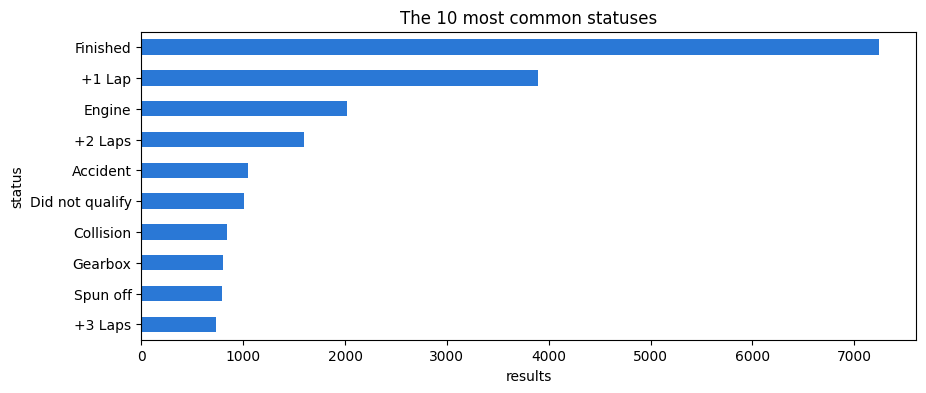

In [27]:
df['status'].value_counts().head(10).sort_values().plot(kind='barh', color='#2a78d6',
                                                        title='The 10 most common statuses')
plt.xlabel('results')
plt.show()

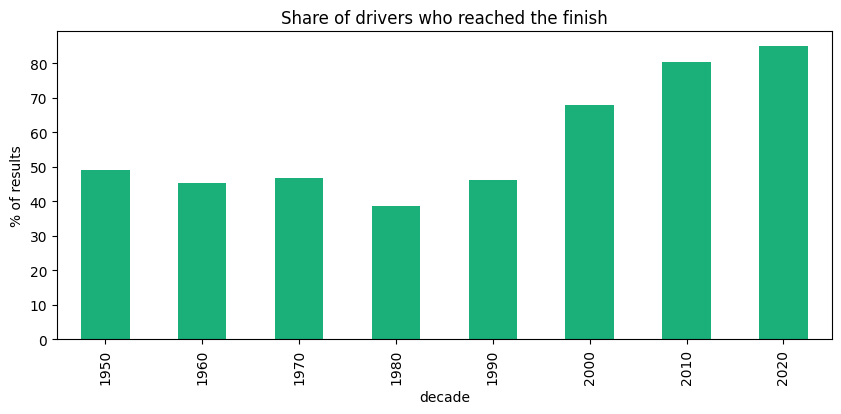

In [28]:
df['finished'] = (df['status'] == 'Finished') | df['status'].str.startswith('+')
df['decade'] = df['year'] // 10 * 10

finish_rate = df.groupby('decade')['finished'].mean() * 100
finish_rate.plot(kind='bar', color='#1baf7a', title='Share of drivers who reached the finish')
plt.ylabel('% of results')
plt.show()

**What the code does**
- `.value_counts().head(10)`: the 10 most common values. `.sort_values()` orders them so the biggest bar is on top.
  `kind='barh'` draws horizontal bars.
- `df['finished'] = ... | ...`: `|` means "or". A driver finished if the status is `Finished`
  **or** starts with `+` (for example `+1 Lap` = finished one lap behind the winner).
- `df['year'] // 10 * 10`: turns a year into its decade. `//` is division without the remainder,
  so 1987 → 198 → 1980.
- `groupby('decade')['finished'].mean() * 100`: the percentage of finishers in each decade.

**What we see**
- "Finished" and "+1 Lap" are the most common statuses, but "Engine" is third: engine failures were very common.
- Until the 1990s **fewer than half** of the drivers reached the finish (39–49%). In the 2010s it was 80%, in the 2020s 85%.

**Why it matters:** F1 changed a lot over time. This is called **drift**: the old data (train) describes
a different sport than the new data (test). A model that learns from 1950–2013 learns partly outdated patterns.

## 9. Legends: who won the most?

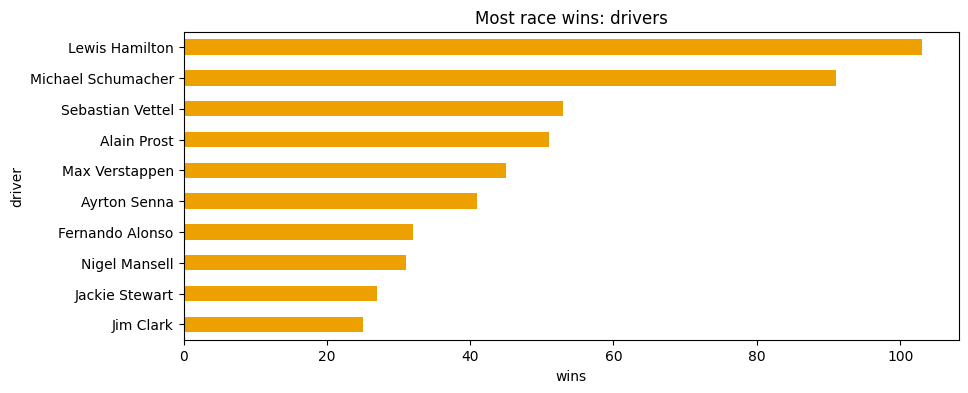

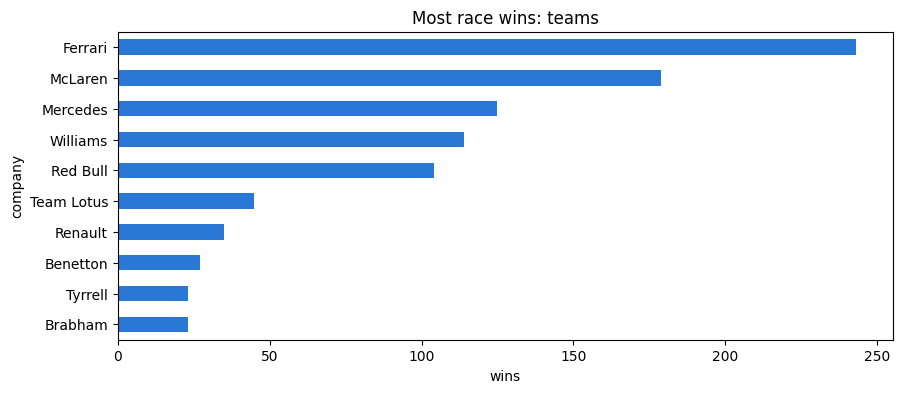

In [29]:
df['driver'] = df['forename'] + ' ' + df['surname']
winners = df[df['won']]

winners['driver'].value_counts().head(10).sort_values().plot(kind='barh', color='#eda100',
                                                             title='Most race wins: drivers')
plt.xlabel('wins')
plt.show()

winners['company'].value_counts().head(10).sort_values().plot(kind='barh', color='#2a78d6',
                                                              title='Most race wins: teams')
plt.xlabel('wins')
plt.show()

**What the code does**
- `df['forename'] + ' ' + df['surname']`: glues first name, a space and surname into one text column.
- `df[df['won']]`: keeps only the rows where `won` is True, i.e. the wins.
- The rest is the same pattern as before: count, take the top 10, sort, draw horizontal bars.

**What we see:** Lewis Hamilton (103 wins) and Michael Schumacher (91) are far ahead of everyone else.
Among teams Ferrari leads (243), followed by McLaren (179) and Mercedes (125).

**Why this chart is useful:** it is a sanity check. The numbers match what F1 fans know, so our way of removing
the copies in section 3 did not break the data.

## 10. Missing values

Many cells in the table are empty. We check every column of the clean table `df`.

Columns with empty cells: 23 out of 56


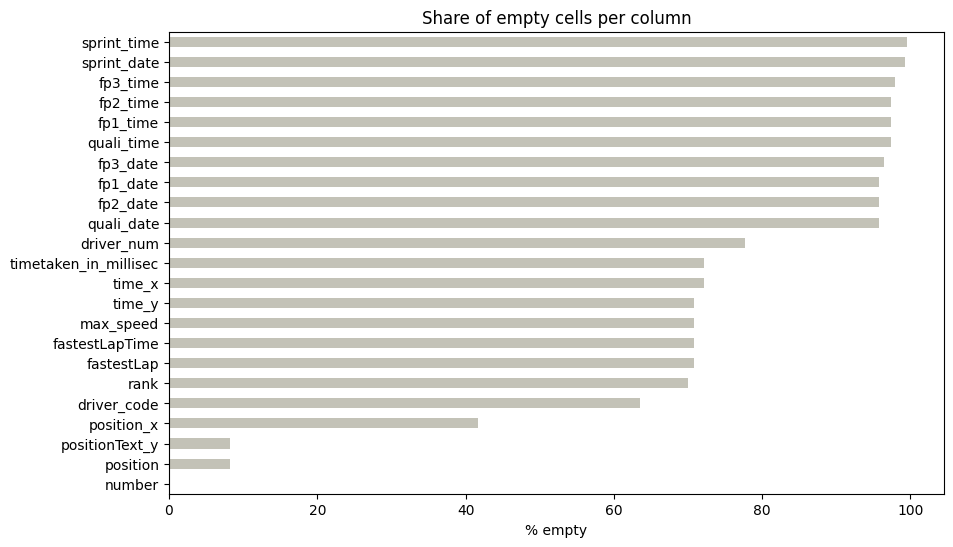

In [30]:
missing = df[raw.columns].isna().mean() * 100
missing = missing[missing > 0].sort_values()
print('Columns with empty cells:', len(missing), 'out of', len(raw.columns))

missing.plot(kind='barh', color='#c3c2b7', figsize=(10, 6), title='Share of empty cells per column')
plt.xlabel('% empty')
plt.show()

**What the code does**
- `df[raw.columns]`: takes only the original 56 columns, without the helper columns we added along the way.
- `.isna()`: True where a cell is empty. `.mean() * 100` gives the percentage of empty cells in each column.
- `missing[missing > 0]`: keeps only the columns that have at least one empty cell. `.sort_values()` orders them.
- `len(raw.columns)`: the number of original columns.

**What we see**
- 23 of the 56 columns have empty cells. The other 33 are complete, including all 11 columns we use.
- **Practice, qualifying and sprint columns** (`fp1…`, `fp2…`, `fp3…`, `quali…`, `sprint…`) are 96–99% empty.
  They are filled only from 2021, and they hold just the dates and hours of the sessions, not their results.
- **Lap data** (`fastestLap`, `fastestLapTime`, `max_speed`, `rank`) is about 70% empty: it is recorded only from 2004.
- `driver_num` and `driver_code` (the driver's permanent number and three-letter code) are 78% and 64% empty:
  older drivers never had them.
- **Race time** (`time_x`, `timetaken_in_millisec`) is 72% empty: only drivers who finished on the same lap
  as the winner get a race time.
- `position_x` is 42% empty: drivers who did not finish have no official position.
- `position` and `positionText_y` are 8% empty: these two columns do not exist in the test file.

**Why it matters:** missing values here are not random. They depend on the era and on whether the driver finished.

## 11. Summary

| ✅ Strengths | ❌ Weaknesses |
|---|---|
| Huge time span: 74 seasons, almost all of F1 history | Every result is copied ~136 times. Must be cleaned first |
| The key columns (`grid`, `positionOrder`, `year`) have no missing values | Small after cleaning: only ~26 thousand results |
| Ready-made split by time: train / validation / test | Unequal classes: 14 times more "rest" than "win" |
| A target that is easy to understand | Misleading names: `racerId` is the race, not the driver |
| Results can be checked against real F1 history | Drift: F1 in 1950 and in 2023 are very different sports |
| | No qualifying results, weather or pit-stop data |

### Five things to remember
1. **Clean first.** 3.5 million rows are really 26,056 results (section 3).
2. **Split by time.** Train = past, test = future. Never shuffle (section 5).
3. **The target has 4 unequal classes:** win / podium / points / rest (section 6).
4. **The starting grid is the strongest clue.** Pole position wins 42% of races, and the simple grid rule
   is right 57% of the time (section 7).
5. **F1 changes over time.** Before the 1990s fewer than half of the drivers finished, today about 85% do (section 8).

## 12. Cheat sheet and practice questions

### Every command used in this notebook

| Command | In plain words |
|---|---|
| `pd.read_csv('file.csv')` | read a file into a table |
| `pd.concat([a, b])` | glue tables together, one under another |
| `len(df)` | number of rows |
| `df.shape` | (rows, columns) |
| `df.head(5)` | show the first 5 rows |
| `df['year']` | take one column |
| `df[['a', 'b']]` | take several columns |
| `df[df['grid'] >= 1]` | filter: keep only rows where the condition is true |
| `&` and <code>&#124;</code> | "and" / "or" between two conditions |
| `df['new'] = ...` | create a new column |
| `.drop_duplicates('resultId')` | keep one row per `resultId` |
| `.nunique()` | how many different values |
| `.min()` `.max()` `.mean()` `.sum()` | smallest, largest, average, total |
| `.value_counts()` | how many times each value appears |
| `.sort_values()` `.sort_index()` | sort by the values / by the labels |
| `.groupby('x')['y'].mean()` | for each value of x: the average of y |
| `.apply(function)` | use a function on every row |
| `pd.crosstab(a, b)` | table counting every combination of a and b |
| `.isna()` | True where a cell is empty |
| `.plot(kind='bar')` | draw a chart (`bar`, `barh`, or a line by default) |
| `plt.title`, `plt.xlabel`, `plt.ylabel`, `plt.legend`, `plt.show` | title, axis names, legend, display |

### Questions you may be asked

**Why are there 3.5 million rows but only 26 thousand results?**
The results table was joined incorrectly with the championship standings table, so every result was copied
about 136 times. We keep one row per `resultId`.

**What is one row of the clean table?**
One driver in one race.

**What does the project predict?**
The class of the final position (`positionOrder`): win, podium, points or rest.

**Why are the files split by time and not randomly?**
Because the model must predict future races from past ones. A random split would let it "see the future".

**What does "imbalanced classes" mean and why is it a problem?**
The classes have very different sizes (58% rest, 4% win). A model can get a high share of correct answers
by ignoring the rare classes, so we need a fairer score (macro-F1).

**Which column is the most useful for prediction?**
`grid`, the starting position. The pole sitter wins 42% of races.

**What is the grid rule?**
"The driver finishes in the class he starts in." It needs no machine learning and is right in 57% of cases.

**What is drift?**
The data changes over time. Example: the share of finishers rose from under 50% to 85%.

**Why is `racerId` confusing?**
It sounds like a driver ID but it identifies the race. The driver is `driverId`.

**What is missing from the dataset?**
Qualifying results, weather, pit stops and tyre strategy.